In [67]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from rich import columns
from sympy import true
from matplotlib import lines



Preprocessing the tabular data

In [17]:

DATA_PATH = "../../data/processed/classifier_dataset.jsonl"
df = pd.read_json(DATA_PATH, lines=True)
df.head(3)

,id,question,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,has_all_query_entities,query_token_count,is_comparison,label
0,hotpotqa_5a7a06935542990198eaf050,Which magazine was started first Arthur's Maga...,0.032522,0.000256,4.5207,0.6667,0,11,1,1
1,hotpotqa_5a879ab05542996e4f30887e,The Oberoi family is part of a hotel company t...,0.032522,0.000000,4.7036,1.0000,1,17,0,1
2,hotpotqa_5a8d7341554299441c6b9fe5,Musician and satirist Allie Goertz wrote a son...,0.032258,0.000480,4.6033,0.6000,0,20,1,1


In [25]:

df.shape
df.info()
df.isna().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3998 entries, 0 to 3997
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      3998 non-null   str    
 1   question                3998 non-null   str    
 2   rrf_score_top1          3998 non-null   float64
 3   rrf_margin              3998 non-null   float64
 4   rrf_score_entropy       3998 non-null   float64
 5   entity_overlap_ratio    3998 non-null   float64
 6   has_all_query_entities  3998 non-null   int64  
 7   query_token_count       3998 non-null   int64  
 8   is_comparison           3998 non-null   int64  
 9   label                   3998 non-null   int64  
dtypes: float64(4), int64(4), str(2)
memory usage: 804.2 KB


id                        0
question                  0
rrf_score_top1            0
rrf_margin                0
rrf_score_entropy         0
entity_overlap_ratio      0
has_all_query_entities    0
query_token_count         0
is_comparison             0
label                     0
dtype: int64

In [26]:
df.describe(include="all")


,id,question,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,has_all_query_entities,query_token_count,is_comparison,label
count,3998,3998,3998.000000,3998.000000,3998.000000,3998.000000,3998.000000,3998.000000,3998.000000,3998.000000
unique,3989,3988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,musique_2hop__79501_217649,What record label does the songwriter of The s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,0.030719,0.002861,4.658940,0.461096,0.248624,15.551526,0.314657,-0.158329
std,NaN,NaN,0.004214,0.004291,0.094631,0.388297,0.432270,7.554272,0.464437,0.837090
min,NaN,NaN,0.016393,0.000000,4.159500,0.000000,0.000000,4.000000,0.000000,-1.000000
25%,NaN,NaN,0.031258,0.000504,4.611600,0.000000,0.000000,11.000000,0.000000,-1.000000
50%,NaN,NaN,0.032522,0.000985,4.685300,0.500000,0.000000,14.000000,0.000000,0.000000
75%,NaN,NaN,0.032787,0.003144,4.731200,0.857100,0.000000,18.000000,1.000000,1.000000


In [34]:
clean_df = df[df["label"]!=-1].reset_index(drop=True)
clean_df = clean_df.drop_duplicates().drop(columns=["question", "id"])
clean_df


,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,has_all_query_entities,query_token_count,is_comparison,label
0,0.032522,0.000256,4.5207,0.6667,0,11,1,1
1,0.032522,0.000000,4.7036,1.0000,1,17,0,1
2,0.032258,0.000480,4.6033,0.6000,0,20,1,1
3,0.028958,0.005265,4.7301,0.0000,0,7,0,0
4,0.031754,0.001276,4.4103,0.6667,0,13,1,0
...,...,...,...,...,...,...,...,...
2226,0.026598,0.002211,4.7429,0.0000,0,11,0,0
2227,0.016393,0.000000,4.7678,0.0000,0,18,1,0
2228,0.032522,0.000000,4.7351,0.5000,0,11,1,1
2229,0.032018,0.000473,4.5643,0.0000,0,9,0,1


In [ ]:
#Great for XGBOOST
# 1. Interaction: Retrieval margin * entity overlap
#clean_df['margin_x_overlap'] = (
#    clean_df['rrf_margin'] * clean_df['entity_overlap_ratio']
#)

# 2. Ratio: Entropy to Top-1 score (measures uncertainty per unit of score)
#clean_df['entropy_top1_ratio'] = clean_df['rrf_score_entropy'] / (
#    clean_df['rrf_score_top1'] + 1e-6
#)

# 3. Question character length (from the text before dropping it)
#clean_df['q_char_len'] = clean_df['question'].str.len()


In [37]:
from ctypes.util import test
FEATURES = [
    'rrf_score_top1',
    'rrf_margin',
    'rrf_score_entropy',
    'entity_overlap_ratio',
    'has_all_query_entities',
    'query_token_count',
    'is_comparison',
]
X = clean_df[FEATURES]
y = clean_df["label"]

# 80% train+val, 20% test (stratified by label)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Now 70% train and 10% val from above 80% split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.125,
    random_state=42,
    stratify=y_train_full,
)

print(
    f"Train: {len(X_train)} | Val: {len(y_val)} | Test: {len(X_test)}"
)

Train: 1561 | Val: 223 | Test: 446


MODEL SPECIFIC FEATURE SCALING: LOGISTIC REGRESSION

In [43]:

from sklearn.preprocessing import RobustScaler, StandardScaler

scaler = RobustScaler()
CONT_COLS = [
    'rrf_score_top1',
    'rrf_margin',
    'rrf_score_entropy',
    'entity_overlap_ratio',
    'query_token_count',
]

# Copy the splits into new variables for scaling
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# FIT ONLY ON TRAIN, TRANSFORM ON VAL & TEST

X_train_scaled[CONT_COLS] = scaler.fit_transform(X_train[CONT_COLS])
X_val_scaled[CONT_COLS] = scaler.transform(X_val[CONT_COLS])
X_test_scaled[CONT_COLS] = scaler.transform(X_test[CONT_COLS])


In [44]:
#saving the splits

PATH = "../../data/processed/splits/"

X_train_scaled.to_csv(f'{PATH}/X_train_tab.csv', index=False)
X_val_scaled.to_csv(f'{PATH}/X_val_tab.csv', index=False)
X_test_scaled.to_csv(f'{PATH}/X_test_tab.csv', index=False)

np.save(f'{PATH}/y_train.npy', y_train)
np.save(f'{PATH}/y_val.npy', y_val)
np.save(f'{PATH}/y_test.npy', y_test)

In [62]:
from sklearn.metrics import classification_report
# Fit logistic regression on scaled data

model_log = LogisticRegression(class_weight="balanced", random_state=42)
model_log.fit(X_train_scaled, y_train)

y_pred = model_log.predict(X_test_scaled)
y_prob = model_log.predict_proba(X_test_scaled)[:1]

print("=========LOGISTIC REGRESSION RESULTS===========")
print(
    classification_report(y_test, y_pred, target_names=["Multi Hop: 0","Single Hop: 1"])
)





=========LOGISTIC REGRESSION RESULTS===========
               precision    recall  f1-score   support

 Multi Hop: 0       0.70      0.65      0.67       219
Single Hop: 1       0.68      0.73      0.70       227

     accuracy                           0.69       446
    macro avg       0.69      0.69      0.69       446
 weighted avg       0.69      0.69      0.69       446



ACCURACY: 0.6883408071748879

=======CONFUSION MATRIX============
[[142  77]
 [ 62 165]]


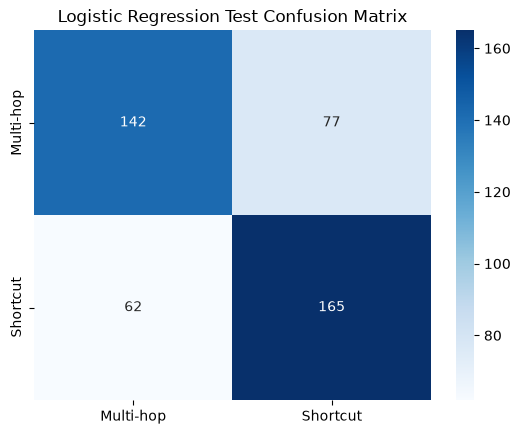

=======ROC AUC============
ROC AUC: 0.6876370365900268


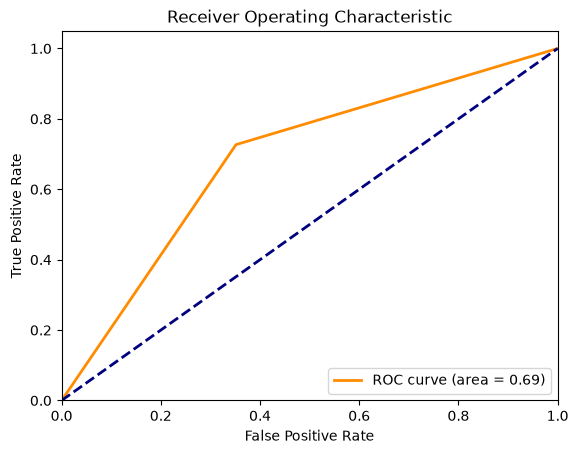

In [51]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
print(f"ACCURACY: {accuracy_score(y_test, y_pred)}\n")

print("=======CONFUSION MATRIX============")
print(f"{confusion_matrix(y_test, y_pred)}")
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Multi-hop', 'Shortcut'],
    yticklabels=['Multi-hop', 'Shortcut'],
)
plt.title('Logistic Regression Test Confusion Matrix')
plt.show()

print("=======ROC AUC============")
auc_roc = roc_auc_score(y_test, y_pred)
print(f"ROC AUC: {auc_roc}")
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc_roc

plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange', lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()




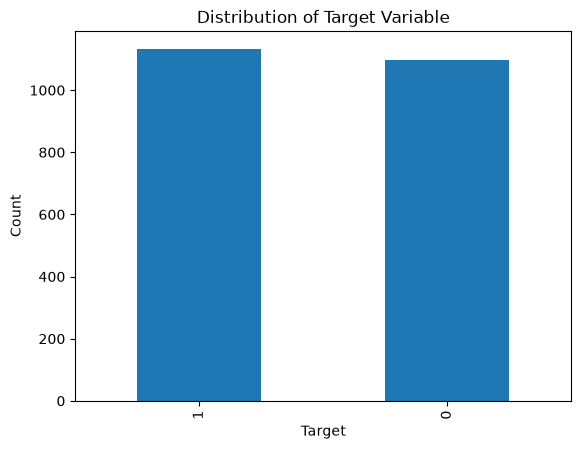

Class Distribution:
label
1    0.508072
0    0.491928
Name: proportion, dtype: float64
Class Imbalance Ratio: 0.97
Skewness: -0.03


In [59]:

# Plot the distribution of the target variable
clean_df["label"].value_counts().plot(kind='bar')
plt.title('Distribution of Target Variable')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

# Calculate class distribution
class_distribution = clean_df['label'].value_counts(normalize=True)
print("Class Distribution:")
print(class_distribution)

# Calculate class imbalance ratio
class_imbalance_ratio = class_distribution[0] / class_distribution[1]
print(f"Class Imbalance Ratio: {class_imbalance_ratio:.2f}")

# Calculate skewness
skewness = clean_df['label'].skew()
print(f"Skewness: {skewness:.2f}")


**XGBOOST CLASSIFICATION MODEL**

In [75]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(
    n_estimators=100,            # 100 trees is plenty for 1.5k rows
    max_depth=3,                 # Keep trees shallow (3 to 4) to capture pairwise interactions without memorizing
    learning_rate=0.05,          # Slow shrinkage for stable step updates
    subsample=0.8,               # Bagging fraction to add stochastic regularization
    colsample_bytree=0.8,        # Sample subset of features per tree
    reg_alpha=0.1,               # L1 regularization to prune dead weight splits
    reg_lambda=1.0,              # L2 regularization
    eval_metric="logloss",
    random_state=42
)

model_xgb.fit(X_train_scaled, y_train)

y_pred_xgb = model_xgb.predict(X_test_scaled)
y_prob_xgb = model_xgb.predict_proba(X_test_scaled)[:1]

print('\n=== XGBOOST TEST RESULTS ===')
print(
    classification_report(
        y_test, y_pred_xgb, target_names=['Multi-hop (0)', 'Shortcut (1)']
    )
)



=== XGBOOST TEST RESULTS ===
               precision    recall  f1-score   support

Multi-hop (0)       0.70      0.63      0.66       219
 Shortcut (1)       0.67      0.74      0.71       227

     accuracy                           0.69       446
    macro avg       0.69      0.69      0.68       446
 weighted avg       0.69      0.69      0.68       446



============CONFUSION MATRIX=================


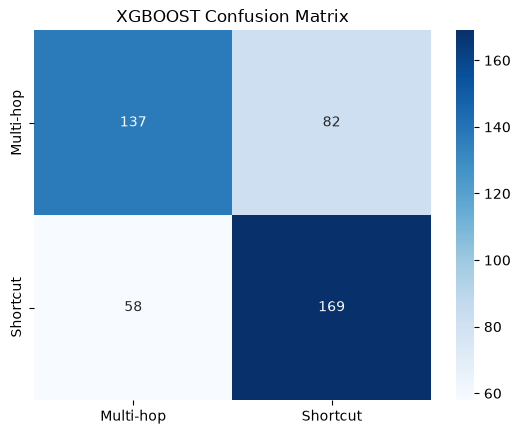

accuracy: 0.6860986547085202


In [77]:
print("============CONFUSION MATRIX=================")
sns.heatmap(
    confusion_matrix(y_test, y_pred_xgb),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Multi-hop', 'Shortcut'],
    yticklabels=['Multi-hop', 'Shortcut'],
)
plt.title('XGBOOST Confusion Matrix')
plt.show()

print(f"accuracy: {accuracy_score(y_test, y_pred_xgb)}")

